<a href="https://colab.research.google.com/github/abrarjahinzihan/Spam-Email-Detection/blob/main/Spam_Email_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spam Email Detection (Medium)

**Goal:** Automatically separate spam and legitimate (ham) emails, and flag phishing / unwanted promotional messages.

**Pipeline**
1. Load dataset from Google Drive
2. Exploratory data analysis
3. Text preprocessing: tokenization, stop-word removal, stemming
4. TF-IDF vectorization
5. Train **Multinomial Naive Bayes** and **Linear SVM**
6. Evaluate (accuracy, precision, recall, F1, confusion matrix, ROC) + cross-validation + hyper-parameter tuning
7. Phishing / promotional detection layer
8. Save the model and predict on new emails

## 1. Setup & Mount Google Drive

In [ ]:
import re, string, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, auc)

sns.set_style("whitegrid")
RANDOM_STATE = 42
print("Libraries loaded")

Libraries loaded ✅


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# CHANGE THIS to the path of your dataset in Google Drive
DATA_PATH = "/content/drive/MyDrive/Untitled Folder 2/spam_emails_5k5.csv"
# Folder where the trained model will be saved
MODEL_DIR = "/content/drive/MyDrive/spam_detector"
import os; os.makedirs(MODEL_DIR, exist_ok=True)

## 2. Load the Dataset
Works with common spam datasets (e.g. `spam.csv` with columns `v1,v2`; `spam_ham_dataset.csv` with `label,text`; or any CSV with one label column and one text column). The label and text columns are auto-detected.

In [ ]:
def read_any_csv(path):
    for enc in ("utf-8", "latin-1", "cp1252"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Could not decode the file")

raw = read_any_csv(DATA_PATH)
print("Raw shape:", raw.shape)
display(raw.head())

Raw shape: (5572, 2)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
def detect_columns(df):
    """Return (label_col, text_col) automatically."""
    label_col, text_col = None, None
    valid = {"spam", "ham", "0", "1", "legitimate", "phishing email", "safe email", "not spam"}
    for c in df.columns:
        vals = set(df[c].dropna().astype(str).str.lower().str.strip().unique())
        if 1 < len(vals) <= 3 and vals.issubset(valid) and label_col is None:
            label_col = c
    obj_cols = [c for c in df.columns if df[c].dtype == object and c != label_col]
    if obj_cols:
        text_col = max(obj_cols, key=lambda c: df[c].dropna().astype(str).str.len().mean())
    return label_col, text_col

label_col, text_col = detect_columns(raw)
print(f"Detected label column: {label_col!r} | text column: {text_col!r}")

df = raw[[label_col, text_col]].copy()
df.columns = ["label_raw", "text"]
df = df.dropna().drop_duplicates().reset_index(drop=True)

def to_binary(v):
    v = str(v).lower().strip()
    return 1 if v in ("spam", "1", "phishing email") else 0

df["label"] = df["label_raw"].apply(to_binary)
df["category"] = df["label"].map({0: "ham", 1: "spam"})
df["text"] = df["text"].astype(str)
print("Clean shape:", df.shape)
df[["category", "text"]].head()

Detected label column: 'Category' | text column: 'Message'
Clean shape: (5157, 4)


,category,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Exploratory Data Analysis

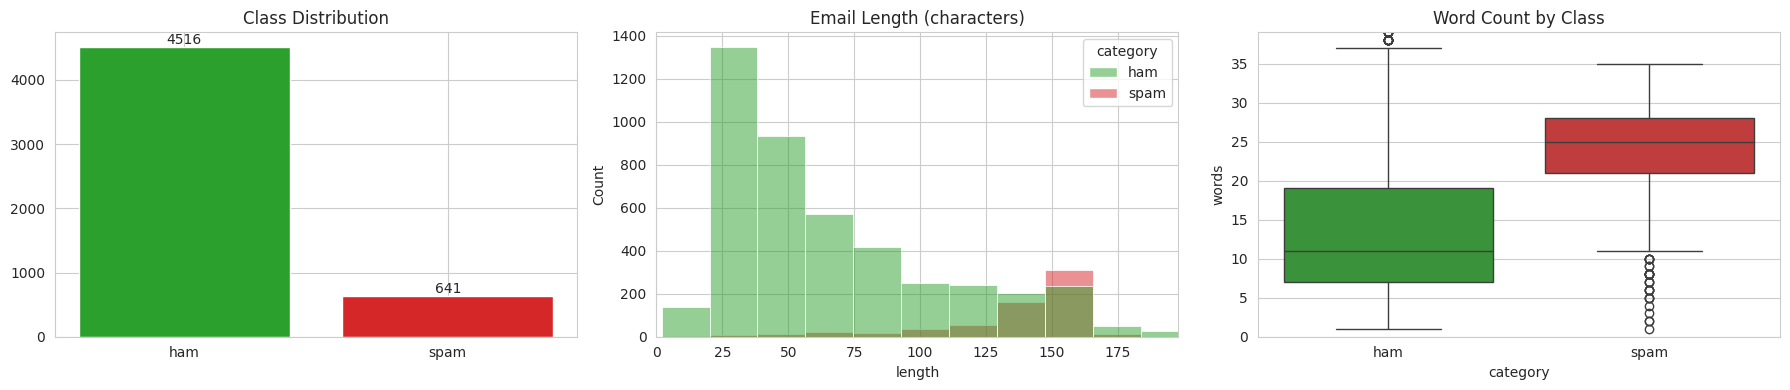

category
ham     0.876
spam    0.124
Name: proportion, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

counts = df["category"].value_counts()
ax[0].bar(counts.index, counts.values, color=["#2ca02c", "#d62728"])
ax[0].set_title("Class Distribution")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, str(v), ha="center", va="bottom")

df["length"] = df["text"].str.len()
df["words"] = df["text"].str.split().str.len()
sns.histplot(data=df, x="length", hue="category", bins=50, ax=ax[1],
             palette={"ham": "#2ca02c", "spam": "#d62728"}, log_scale=(False, False))
ax[1].set_title("Email Length (characters)"); ax[1].set_xlim(0, df["length"].quantile(0.98))

sns.boxplot(data=df, x="category", y="words", ax=ax[2], palette={"ham": "#2ca02c", "spam": "#d62728"})
ax[2].set_title("Word Count by Class"); ax[2].set_ylim(0, df["words"].quantile(0.98))
plt.tight_layout(); plt.show()

print(df["category"].value_counts(normalize=True).round(3))

## 4. Text Preprocessing
Steps: lowercase → replace URLs / emails / numbers with tokens → remove punctuation → **tokenization** → **stop-word removal** → **stemming**.

In [ ]:
STOP_WORDS = set(stopwords.words("english"))
stemmer = PorterStemmer()
tokenizer = RegexpTokenizer(r"[a-z]+")

URL_RE   = re.compile(r"(https?://\S+|www\.\S+)")
EMAIL_RE = re.compile(r"\S+@\S+")
NUM_RE   = re.compile(r"\d+")

def clean_text(text):
    text = str(text).lower()
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = NUM_RE.sub(" numtoken ", text)
    tokens = tokenizer.tokenize(text)                                   # tokenization
    tokens = [t for t in tokens if t not in STOP_WORDS and len(t) > 1]  # stop-word removal
    tokens = [stemmer.stem(t) for t in tokens]                          # stemming
    return " ".join(tokens)

sample = df["text"].iloc[0]
print("ORIGINAL:\n", sample[:300])
print("\nCLEANED:\n", clean_text(sample)[:300])

ORIGINAL:
 Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

CLEANED:
 go jurong point crazi avail bugi great world la buffet cine got amor wat


In [ ]:
df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)
print("Rows after cleaning:", len(df))
df[["category", "clean_text"]].head()

Rows after cleaning: 5148


,category,clean_text
0,ham,go jurong point crazi avail bugi great world l...
1,ham,ok lar joke wif oni
2,spam,free entri numtoken wkli comp win fa cup final...
3,ham,dun say earli hor alreadi say
4,ham,nah think goe usf live around though


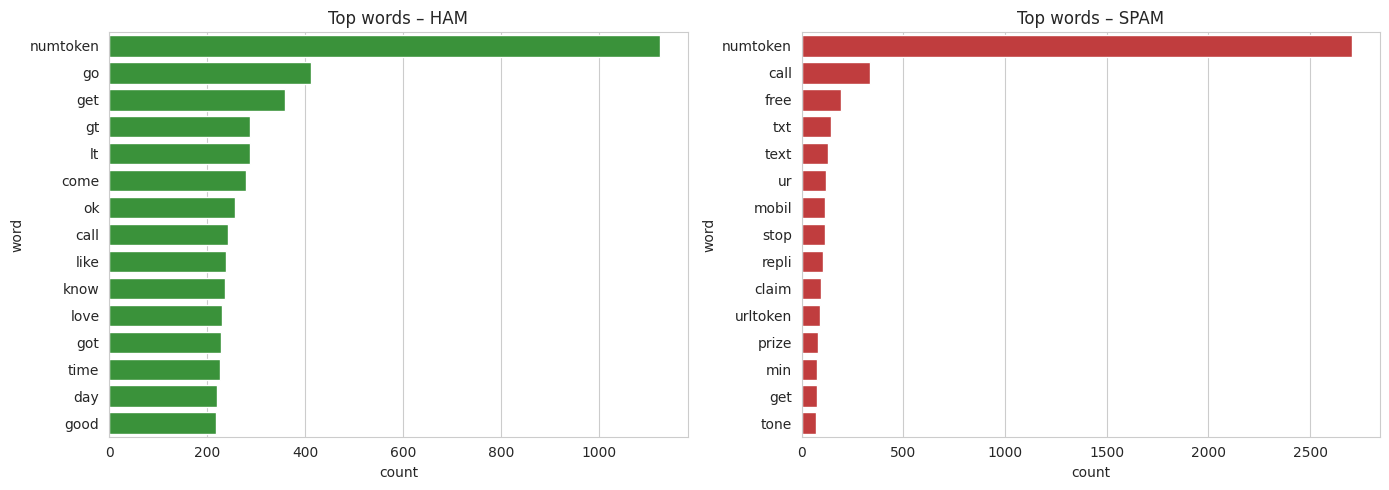

In [ ]:
from collections import Counter
def top_words(cat, n=15):
    c = Counter(" ".join(df.loc[df.category == cat, "clean_text"]).split())
    return pd.DataFrame(c.most_common(n), columns=["word", "count"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_words("ham"),  y="word", x="count", ax=ax[0], color="#2ca02c"); ax[0].set_title("Top words – HAM")
sns.barplot(data=top_words("spam"), y="word", x="count", ax=ax[1], color="#d62728"); ax[1].set_title("Top words – SPAM")
plt.tight_layout(); plt.show()

## 5. Train / Test Split & TF-IDF Vectorization

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=10000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)
print("TF-IDF matrix:", X_train_tfidf.shape)

Train: 4118 | Test: 1030
TF-IDF matrix: (4118, 5842)


## 6. Train Models: Multinomial Naive Bayes & Linear SVM

In [ ]:
nb  = MultinomialNB(alpha=0.1).fit(X_train_tfidf, y_train)
svm = LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_tfidf, y_train)

preds = {"Multinomial NB": nb.predict(X_test_tfidf), "Linear SVM": svm.predict(X_test_tfidf)}

rows = []
for name, p in preds.items():
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall":    recall_score(y_test, p),
                 "F1-score":  f1_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

for name, p in preds.items():
    print(f"\n===== {name} =====")
    print(classification_report(y_test, p, target_names=["ham", "spam"]))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial NB,0.9922,0.9918,0.9453,0.9680
Linear SVM,0.9932,0.9919,0.9531,0.9721



===== Multinomial NB =====
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       902
        spam       0.99      0.95      0.97       128

    accuracy                           0.99      1030
   macro avg       0.99      0.97      0.98      1030
weighted avg       0.99      0.99      0.99      1030


===== Linear SVM =====
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       902
        spam       0.99      0.95      0.97       128

    accuracy                           0.99      1030
   macro avg       0.99      0.98      0.98      1030
weighted avg       0.99      0.99      0.99      1030



## 7. Evaluation: Confusion Matrices & ROC Curves

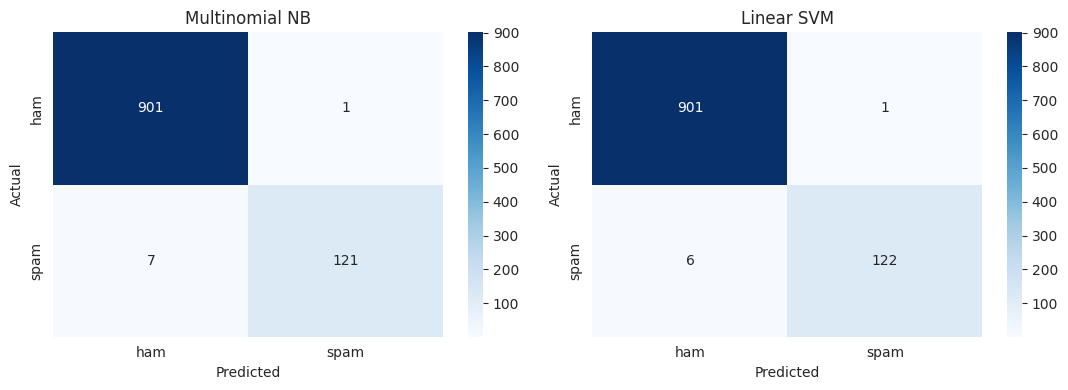

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (name, p) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", ax=a,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

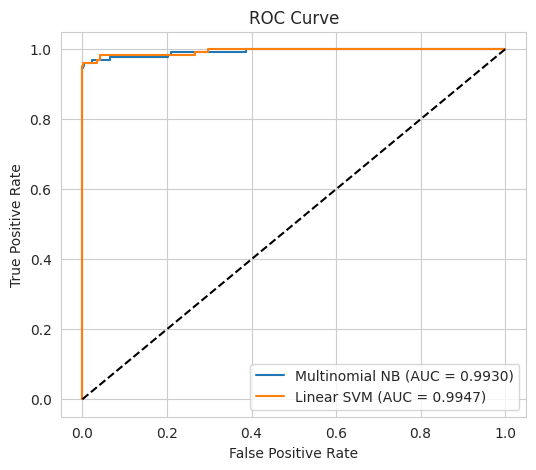

In [ ]:
plt.figure(figsize=(6, 5))
scores = {"Multinomial NB": nb.predict_proba(X_test_tfidf)[:, 1],
          "Linear SVM": svm.decision_function(X_test_tfidf)}
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve")
plt.legend(); plt.show()

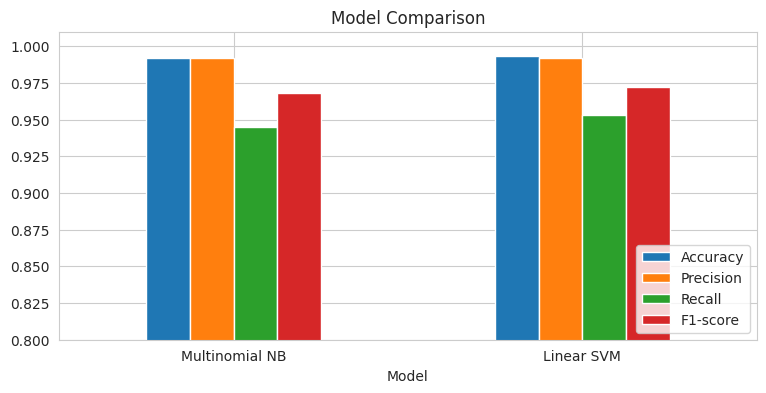

In [ ]:
results.plot(kind="bar", figsize=(9, 4), ylim=(0.8, 1.01), rot=0)
plt.title("Model Comparison"); plt.legend(loc="lower right"); plt.show()

## 8. Hyper-parameter Tuning & Cross-Validation

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2)), ("clf", clf)])

nb_grid = GridSearchCV(make_pipe(MultinomialNB()),
    {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__max_features": [5000, 10000],
     "clf__alpha": [0.01, 0.1, 0.5, 1.0]},
    cv=skf, scoring="f1", n_jobs=-1).fit(X_train, y_train)

svm_grid = GridSearchCV(make_pipe(LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)),
    {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__max_features": [5000, 10000],
     "clf__C": [0.1, 0.5, 1, 5]},
    cv=skf, scoring="f1", n_jobs=-1).fit(X_train, y_train)

print("Best NB params :", nb_grid.best_params_, "| CV F1 =", round(nb_grid.best_score_, 4))
print("Best SVM params:", svm_grid.best_params_, "| CV F1 =", round(svm_grid.best_score_, 4))

Best NB params : {'clf__alpha': 0.1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)} | CV F1 = 0.9376
Best SVM params: {'clf__C': 5, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 2)} | CV F1 = 0.9341


In [ ]:
final = {}
for name, g in {"Multinomial NB (tuned)": nb_grid, "Linear SVM (tuned)": svm_grid}.items():
    p = g.best_estimator_.predict(X_test)
    final[name] = {"Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                   "Recall": recall_score(y_test, p), "F1-score": f1_score(y_test, p)}
final_df = pd.DataFrame(final).T.round(4)
display(final_df)

best_name = final_df["F1-score"].idxmax()
best_model = (svm_grid if "SVM" in best_name else nb_grid).best_estimator_
print("🏆 Best model:", best_name)

cv_scores = cross_val_score(best_model, X_train, y_train, cv=skf, scoring="accuracy")
print(f"5-fold CV accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

,Accuracy,Precision,Recall,F1-score
Multinomial NB (tuned),0.9922,0.9918,0.9453,0.9680
Linear SVM (tuned),0.9932,0.9919,0.9531,0.9721


🏆 Best model: Linear SVM (tuned)
5-fold CV accuracy: 0.9840 ± 0.0047


## 9. Most Informative Features

In [ ]:
# Naive Bayes: words that push an email toward spam vs ham
vocab = np.array(tfidf.get_feature_names_out())
diff = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
top_spam = vocab[np.argsort(diff)[-15:][::-1]]
top_ham  = vocab[np.argsort(diff)[:15]]
print("🔴 Strong SPAM indicators:", ", ".join(top_spam))
print("🟢 Strong HAM indicators :", ", ".join(top_ham))

🔴 Strong SPAM indicators: claim, prize, tone, numtoken prize, guarante, numtoken cash, box numtoken, ppm, rington, stop numtoken, numtoken ppm, numtoken claim, mobil numtoken, cs, pobox numtoken
🟢 Strong HAM indicators : gt, lt, lt gt, da, lor, later, lol, alreadi, anyth, sure, someth, sleep, watch, realli, fine


## 10. Phishing & Promotional Message Detection
The ML model decides **spam vs ham**. On top of that, a rule-based layer scores phishing indicators (credential requests, urgency, suspicious / shortened / IP-based links, brand impersonation). Spam that scores high on these is labeled **Phishing**, other spam is labeled **Promotional**.

In [ ]:
PHISH_KEYWORDS = {
    "credentials": ["verify your account", "confirm your identity", "password", "login", "log in", "sign in",
                    "update your account", "account suspended", "account locked", "security alert",
                    "unusual activity", "bank account", "credit card", "social security", "ssn", "pin"],
    "urgency":     ["urgent", "immediately", "within 24 hours", "act now", "final notice", "expires",
                    "limited time", "suspended", "verify now", "action required"],
    "lure":        ["click here", "click below", "claim your", "you have won", "winner", "refund",
                    "invoice attached", "wire transfer", "gift card", "inheritance"],
}
PROMO_KEYWORDS = ["free", "discount", "sale", "offer", "deal", "buy now", "% off", "coupon", "promo",
                  "subscribe", "unsubscribe", "winner", "prize", "cheap", "save", "bonus", "order now"]
SHORTENERS = ["bit.ly", "tinyurl", "goo.gl", "t.co", "ow.ly", "is.gd", "cutt.ly", "rb.gy"]
BRANDS = ["paypal", "amazon", "apple", "microsoft", "google", "netflix", "facebook", "bank", "dhl", "fedex"]

def phishing_features(text):
    t = str(text).lower()
    urls = URL_RE.findall(t)
    f = {
        "credential_hits": sum(k in t for k in PHISH_KEYWORDS["credentials"]),
        "urgency_hits":    sum(k in t for k in PHISH_KEYWORDS["urgency"]),
        "lure_hits":       sum(k in t for k in PHISH_KEYWORDS["lure"]),
        "num_urls":        len(urls),
        "ip_url":          int(any(re.search(r"https?://\d{1,3}(\.\d{1,3}){3}", u) for u in urls)),
        "short_url":       int(any(s in u for u in urls for s in SHORTENERS)),
        "http_only":       int(any(u.startswith("http://") for u in urls)),
        "at_in_url":       int(any("@" in u for u in urls)),
        "brand_mention":   int(any(b in t for b in BRANDS)),
        "promo_hits":      sum(k in t for k in PROMO_KEYWORDS),
    }
    f["phish_score"] = (2 * f["credential_hits"] + f["urgency_hits"] + f["lure_hits"]
                        + 2 * f["ip_url"] + 2 * f["short_url"] + f["http_only"]
                        + 2 * f["at_in_url"] + (f["num_urls"] > 0) * (f["brand_mention"] + 1))
    return f

PHISH_THRESHOLD = 5

def analyze_email(text, model=None):
    """Classify an email as Ham / Promotional Spam / Phishing."""
    model = model or best_model
    spam = int(model.predict([clean_text(text)])[0])
    feats = phishing_features(text)
    if feats["phish_score"] >= PHISH_THRESHOLD and (spam == 1 or feats["credential_hits"] >= 1):
        verdict = "🚨 PHISHING"
    elif spam == 1:
        verdict = "📢 SPAM (Promotional)"
    else:
        verdict = "✅ HAM (Legitimate)"
    return {"verdict": verdict, "ml_spam": spam, "phish_score": feats["phish_score"], "details": feats}

In [ ]:
samples = [
    "Hi John, are we still meeting tomorrow at 10am to discuss the project report? Thanks, Sarah",
    "WINNER!! You have won a FREE $1000 gift card. Click here http://bit.ly/claim-now to claim your prize. Limited time offer!",
    "URGENT: Your PayPal account has been suspended due to unusual activity. Verify your account password immediately: http://192.168.4.7/paypal/login",
    "Huge SALE this weekend! 50% off all items, buy now and save. Unsubscribe anytime.",
    "Please find attached the minutes of yesterday's meeting. Let me know if anything is missing.",
]
for s in samples:
    r = analyze_email(s)
    print(f"{r['verdict']:<24} phish_score={r['phish_score']:<3} | {s[:80]}...")

✅ HAM (Legitimate)       phish_score=0   | Hi John, are we still meeting tomorrow at 10am to discuss the project report? Th...
🚨 PHISHING               phish_score=10  | WINNER!! You have won a FREE $1000 gift card. Click here http://bit.ly/claim-now...
🚨 PHISHING               phish_score=16  | URGENT: Your PayPal account has been suspended due to unusual activity. Verify y...
✅ HAM (Legitimate)       phish_score=0   | Huge SALE this weekend! 50% off all items, buy now and save. Unsubscribe anytime...
✅ HAM (Legitimate)       phish_score=0   | Please find attached the minutes of yesterday's meeting. Let me know if anything...


## 11. Evaluate Phishing Layer on the Test Set (optional sanity check)

In [ ]:
test_idx = X_test.index
test_raw = df.loc[test_idx, "text"]
verdicts = test_raw.apply(lambda t: analyze_email(t)["verdict"])
print(pd.crosstab(df.loc[test_idx, "category"], verdicts))

text      ✅ HAM (Legitimate)  📢 SPAM (Promotional)
category                                          
ham                      901                     1
spam                       6                   122


## 12. Save the Model

In [ ]:
joblib.dump(best_model, f"{MODEL_DIR}/spam_model.joblib")
print("Saved to:", f"{MODEL_DIR}/spam_model.joblib")

# To reuse later:
# model = joblib.load(f"{MODEL_DIR}/spam_model.joblib")
# model.predict([clean_text("your email text here")])

Saved to: /content/drive/MyDrive/spam_detector/spam_model.joblib


## 13. Try It Yourself

In [ ]:
email_text = input("Paste an email to analyze:\n")
r = analyze_email(email_text)
print("\nVerdict:", r["verdict"], "| phishing score:", r["phish_score"])
print({k: v for k, v in r["details"].items() if v})

Paste an email to analyze:
Hey there,    It’s officially spooky season in the Awesomeverse! Whether you're braving the elements to trick-or-treat, handing out full-size candy bars like the "cool" neighbor that you are, or getting a jump scare from the sound of the doorbell, we hope your Halloween is frightfully fun.    Happy haunting,    The Font Awesome Candy Corn Defense League

Verdict: ✅ HAM (Legitimate) | phishing score: 0
{}


## ✅ Summary
- **Preprocessing:** tokenization, stop-word removal, stemming, TF-IDF (unigrams + bigrams)
- **Models:** Multinomial Naive Bayes and Linear SVM, tuned with 5-fold GridSearchCV
- **Metrics:** accuracy, precision, recall, F1, confusion matrix, ROC-AUC
- **Security layer:** rule-based phishing scoring + promotional-spam detection
- **Deliverable:** reusable `analyze_email()` function and a saved model in Google Drive